<div style='background-color: #E1F5FE; border-left:4px solid #2196F3; border-radius:6px; padding:14px 18px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">Feature building and preprocessing</h1>
<p style="color:#243038; margin:0.4em 0;"><strong>LTAT.02.002 Introduction to Data Science - Autumn 2026</strong></p>
<p style="color:#243038; margin:0.4em 0;"><strong>Team members: Nazar Zavrin, Oliver Albert Hallik, Kerreth Arula</strong></p>

</div>

This notebook turns `cleaned_flights_for_modelling.parquet` into `features.parquet`, the input for the modelling notebooks.

**In this notebook:** only steps that are computed row by row are done here. Anything that learns from the data is fitted on the training data only and therefore is done in the modelling pipeline in different notebooks. This keeps `features.parquet` free of data leakage. One-hot encoding is done in the modelling pipeline because a one-hot encoded parquet file would be very large and is better done in-memory.

The one exception is the outlier threshold. It is computed from the training split only, and rows are only flagged here, removing them is done in modelling notebooks, because we still need them in the test set. The split is decided here, but only marked with columns so splits can be made identically in other notebooks or ignored if needed.

**Left for the modelling notebook:** choosing the feature columns (dropping `itinerary_id`, `flight_number`, raw timestamps, `price`), encoding, scaling and model fitting.

## 1. Setup and loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

INPUT_FILE = Path.cwd() / "cleaned_flights_for_modelling.parquet"
OUTPUT_FILE = Path.cwd() / "features.parquet"
SAMPLE_FILE = Path.cwd() / "features_sample.parquet"

RANDOM_STATE = 42

The dataset has ~20.4M rows. Text columns such as `src` or `airline_name` repeat the same few values millions of times, so they are converted to the `category` dtype right after loading. This stores every distinct value once and keeps memory usage manageable. The remaining dtype optimisation happens in section 8.

In [2]:
df = pd.read_parquet(INPUT_FILE)

TEXT_COLUMNS = ["region_from", "region_to", "airline_code", "airline_name",
                "aircraft", "src", "dst", "flight_number"]
df[TEXT_COLUMNS] = df[TEXT_COLUMNS].astype("category")

print(df.shape)
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
df.head()

(20381571, 18)
Memory usage: 2.23 GB


,itinerary_id,price_datetime,price,departure_date,region_from,region_to,is_best,airline_code,flight_number,airline_name,aircraft,src,dst,departure_datetime,arrival_datetime,travel_time,emissions,days_to_departure
0,FR8257-2025-05-03-RIX-PRG,2025-05-02 22:58:11.409667,87.989998,2025-05-03,Baltics,Eastern,1,FR,FR8257,Ryanair,Boeing 737,RIX,PRG,2025-05-03 09:20:00,2025-05-03 10:20:00,120,92686.0,1
1,BT481-2025-05-03-RIX-PRG,2025-05-02 22:58:11.409719,159.320007,2025-05-03,Baltics,Eastern,1,BT,BT481,Air Baltic,Airbus A220-300 Passenger,RIX,PRG,2025-05-03 18:00:00,2025-05-03 18:50:00,110,107403.0,1
2,LO794-2025-05-03-RIX-WAW,2025-05-02 22:58:11.409754,222.320007,2025-05-03,Baltics,Eastern,1,LO,LO794,LOT,Embraer 195 E2,RIX,WAW,2025-05-03 05:50:00,2025-05-03 06:10:00,80,71509.0,1
3,LO782-2025-05-03-RIX-WAW,2025-05-02 22:58:11.409798,222.320007,2025-05-03,Baltics,Eastern,1,LO,LO782,LOT,Embraer 195,RIX,WAW,2025-05-03 18:30:00,2025-05-03 18:45:00,75,81669.0,1
4,BT611-2025-05-03-RIX-ATH,2025-05-02 22:58:11.409839,358.320007,2025-05-03,Baltics,Eastern,0,BT,BT611,Air Baltic,Airbus A220-300 Passenger,RIX,ATH,2025-05-03 14:40:00,2025-05-03 17:55:00,195,198739.0,1


## 2. Cleaning

### 2.1 Unknown aircraft

The NaN values were already removed in the cleaning notebook, but about 3.6k rows still have an empty string as `aircraft`. We replace it with an explicit `"Unknown"` value. The rows are kept because the aircraft is the only missing piece of information, no need to drop the rows.

In [3]:
print("Empty aircraft values before:", (df["aircraft"] == "").sum())

df["aircraft"] = df["aircraft"].astype("string").str.strip()
df["aircraft"] = df["aircraft"].replace("", "Unknown").astype("category")

print("Empty aircraft values after: ", (df["aircraft"] == "").sum())
print("Rows with 'Unknown' aircraft:", (df["aircraft"] == "Unknown").sum())

Empty aircraft values before: 3638
Empty aircraft values after:  0
Rows with 'Unknown' aircraft: 3638


### 2.2 One airline = one category

`airline_code` and `airline_name` describe the same thing but do not match one-to-one:

| airline_name | airline_code |
|---|---|
| Norwegian | D8, DY |
| Wizz Air | W6, W4, W9 |
| Transavia | HV, TO |
| Laudamotion / FLYONE Romania | both use OE |

The extra codes are subsidiaries with their own licences (e.g. Wizz Air Hungary / Malta / UK), but they sell tickets under one brand and pricing. If we used the code, the model would split one airline into several small categories, and in the `OE` case it would merge two unrelated airlines.

Because of this, we will use `airline_name` as the airline feature, renamed to `airline`, and drop `airline_code`.

In [4]:
codes_per_name = df.groupby("airline_name", observed=True)["airline_code"].nunique()
names_per_code = df.groupby("airline_code", observed=True)["airline_name"].nunique()
print("Airline names with several codes:\n", codes_per_name[codes_per_name > 1], "\n")
print("Airline codes shared by several names:\n", names_per_code[names_per_code > 1], "\n")

df = df.rename(columns={"airline_name": "airline"}).drop(columns="airline_code")
print("Number of airlines:", df["airline"].nunique())

Airline names with several codes:
 airline_name
Norwegian    2
Transavia    2
Wizz Air     3
Name: airline_code, dtype: int64 

Airline codes shared by several names:
 airline_code
OE    2
Name: airline_name, dtype: int64 

Number of airlines: 55


## 3. Target: `log_price`

`price` is heavily right-skewed: the median is ~145 EUR but the top 1% of prices is above ~1,950 EUR and the maximum is ~19,000 EUR (skewness ≈ 7.7). With a squared-error loss, the few very expensive tickets would dominate training. After a log transform the distribution is close to symmetric (skewness ≈ 0.5), and errors become relative (being 20 EUR off on a 50 EUR ticket counts as much as 200 EUR off on a 500 EUR ticket).

Models are trained on `log_price`. Predictions are transformed back with `np.exp` so that errors are reported in EUR. The original `price` column is kept for that purpose.

In [5]:
df["log_price"] = np.log(df["price"])

print(f"Median price:                {df['price'].median():8.2f} EUR")
print(f"Mean price:                  {df['price'].mean():8.2f} EUR")
print(f"99th percentile (top 1 %):   {df['price'].quantile(0.99):8.2f} EUR")
print(f"Maximum price:               {df['price'].max():8.2f} EUR")
print(f"Skewness of price:           {df['price'].skew():8.2f}")
print(f"Skewness of log_price:       {df['log_price'].skew():8.2f}")

Median price:                  145.23 EUR
Mean price:                    244.25 EUR
99th percentile (top 1 %):    1957.88 EUR
Maximum price:               19345.81 EUR
Skewness of price:               7.74
Skewness of log_price:           0.48


The histograms below show the same thing visually: `price` has a long right tail (the x-axis is cut at the 99.9th percentile, otherwise the bulk of the data would be squeezed into the first bar), while `log_price` is close to a bell shape.

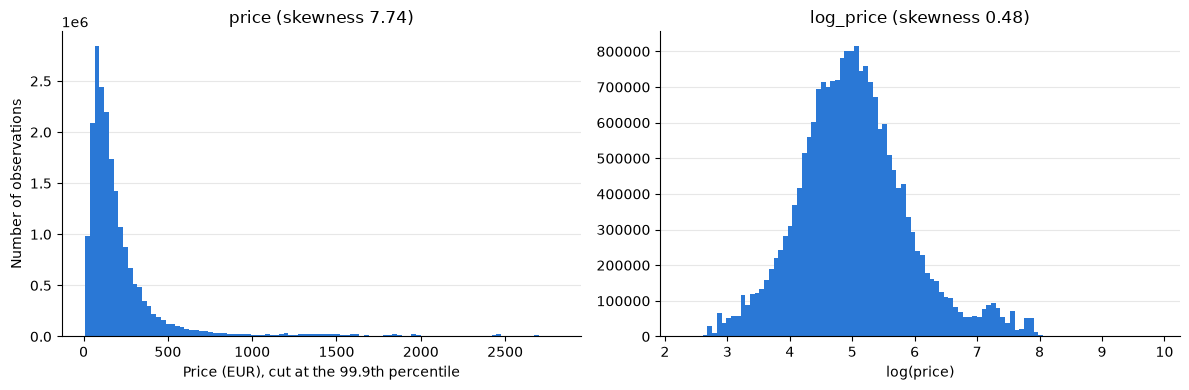

In [6]:
import matplotlib.pyplot as plt

BAR_COLOR = "#2a78d6"
price_cutoff = df["price"].quantile(0.999)

fig, (ax_raw, ax_log) = plt.subplots(1, 2, figsize=(12, 4))

ax_raw.hist(df.loc[df["price"] <= price_cutoff, "price"], bins=100, color=BAR_COLOR)
ax_raw.set_title(f"price (skewness {df['price'].skew():.2f})")
ax_raw.set_xlabel("Price (EUR), cut at the 99.9th percentile")
ax_raw.set_ylabel("Number of observations")

ax_log.hist(df["log_price"], bins=100, color=BAR_COLOR)
ax_log.set_title(f"log_price (skewness {df['log_price'].skew():.2f})")
ax_log.set_xlabel("log(price)")

for ax in (ax_raw, ax_log):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 4. Route features

### 4.1 Flight distance in km

Distance is one of the main drivers of ticket price. The dataset has only 53 airports, so their coordinates (latitude, longitude) are hard-coded below. They were taken from https://ourairports.com

The distance is the great-circle distance computed with the haversine formula:

$$d = 2R \cdot \arcsin\left(\sqrt{\sin^2\frac{\Delta\varphi}{2} + \cos\varphi_1 \cos\varphi_2 \sin^2\frac{\Delta\lambda}{2}}\right), \quad R = 6371 \text{ km}$$

The distance only depends on the route, so it is computed once per unique (`src`, `dst`) pair (~1,100 routes) and then merged onto the 20M rows. This is much faster than computing it on every row.

In [7]:
df["src"].unique()

['RIX', 'TLL', 'VNO', 'KUN', 'PRG', ..., 'GLA', 'NYO', 'TRF', 'VLC', 'EWR']
Length: 47
Categories (47, str): ['AMS', 'ARN', 'ATH', 'ATL', ..., 'TRF', 'VLC', 'VNO', 'WAW']

In [8]:
AIRPORT_COORDS = {  #code: (latitude, longitude)
    "AMS": (52.3086, 4.7639), 
    "ARN": (59.6519, 17.9186), 
    "ATH": (37.9364, 23.9445), 
    "ATL": (33.6367, -84.4279), 
    "BBU": (44.5032, 26.1021),  
    "BCN": (41.2971, 2.0785),  
    "BGY": (45.6739, 9.7042),  
    "BHX": (52.4539, -1.7480), 
    "BRU": (50.9010, 4.4856),
    "BUD": (47.4369, 19.2556),
    "BVA": (49.4544, 2.1128),  
    "CDG": (49.0128, 2.5500), 
    "CPH": (55.6179, 12.6560), 
    "DAL": (32.8459, -96.8509), 
    "DEN": (39.8617, -104.6732),
    "DFW": (32.8972, -97.0377), 
    "DUB": (53.4213, -6.2701), 
    "DUS": (51.2895, 6.7668),  
    "EWR": (40.6925, -74.1687),  
    "FRA": (50.0264, 8.5431), 
    "GLA": (55.8719, -4.4331),
    "HEL": (60.3172, 24.9633),
    "JFK": (40.6399, -73.7787),
    "KUN": (54.9639, 24.0848),
    "LAX": (33.9425, -118.4080),
    "LCY": (51.5053, 0.0553), 
    "LGA": (40.7772, -73.8726),
    "LGW": (51.1481, -0.1903),  
    "LHR": (51.4706, -0.4619),  
    "LIN": (45.4451, 9.2767),  
    "LIS": (38.7813, -9.1359),  
    "LTN": (51.8747, -0.3683), 
    "MAD": (40.4936, -3.5668), 
    "MAN": (53.3537, -2.2750),  
    "MDW": (41.7856, -87.7527), 
    "MUC": (48.3538, 11.7861),   
    "MXP": (45.6306, 8.7281),     
    "NYO": (58.7886, 16.9122), 
    "OPO": (41.2481, -8.6814),   
    "ORD": (41.9769, -87.9082),   
    "ORY": (48.7253, 2.3594),     
    "OSL": (60.1939, 11.1004),   
    "OTP": (44.5722, 26.1022),  
    "PRG": (50.1008, 14.2600),   
    "RIX": (56.9236, 23.9711),    
    "SFO": (37.6188, -122.3754),  
    "STN": (51.8850, 0.2350),   
    "TLL": (59.4133, 24.8328),    
    "TRF": (59.1867, 10.2586), 
    "VLC": (39.4893, -0.4816),   
    "VNO": (54.6341, 25.2858),    
    "WAW": (52.1657, 20.9671),   
    "WMI": (52.4511, 20.6518),    
}


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


# Every airport in the data must have coordinates, otherwise the distance would be NaN
airports_in_data = set(df["src"].unique()) | set(df["dst"].unique())
missing = airports_in_data - AIRPORT_COORDS.keys()
assert not missing, f"Missing coordinates for: {missing}"

# Compute the distance once per route, then merge it onto all rows
routes = df[["src", "dst"]].drop_duplicates().astype(str).reset_index(drop=True)
src_lat, src_lon = zip(*routes["src"].map(AIRPORT_COORDS))
dst_lat, dst_lon = zip(*routes["dst"].map(AIRPORT_COORDS))
routes["distance_km"] = haversine_km(np.array(src_lat), np.array(src_lon),
                                     np.array(dst_lat), np.array(dst_lon)).round(1)

route_distance = routes.set_index(["src", "dst"])["distance_km"]
df["distance_km"] = route_distance.reindex(
    pd.MultiIndex.from_arrays([df["src"].astype(str), df["dst"].astype(str)])
).to_numpy()

print("Rows without distance:", df["distance_km"].isna().sum())
routes.sort_values("distance_km").iloc[[0, len(routes) // 2, -1]]

Rows without distance: 0


,src,dst,distance_km
233,HEL,TLL,100.8
536,AMS,MAD,1458.6
316,ATH,LAX,11126.9


The shortest route, a median route and the longest route are shown above.

In [9]:
print(f"Correlation distance_km vs travel_time: {df['distance_km'].corr(df['travel_time']):.3f}")

Correlation distance_km vs travel_time: 0.994


### 4.2 Route as a category

A route (e.g. `RIX-AMS`) captures things that `src` and `dst` on their own do not, such as competition on that route or how popular it is. The model can only learn these as a combination of origin and destination, so `route` is added as an extra categorical feature (about 1,100 values).

In [10]:
df["route"] = (df["src"].astype(str) + "-" + df["dst"].astype(str)).astype("category")
print("Number of routes:", df["route"].nunique())

Number of routes: 1094


### 4.3 Emissions per km

Dividing `emissions` by distance gives grams of CO₂ per km. This describes the aircraft and load rather than the distance (e.g. small regional planes or heavy long-haul aircraft have higher values), which may relate to price differently.

The modelling notebooks can then choose between `emissions` and `emissions_per_km`.

In [12]:
df["emissions_per_km"] = df["emissions"] / df["distance_km"]

print(df["emissions_per_km"].describe().round(1))

count    20381571.0
mean          108.5
std            38.8
min            34.8
25%            83.0
50%           100.6
75%           127.8
max           548.2
Name: emissions_per_km, dtype: float64


## 5. Time features

Raw timestamps cannot be used directly by most models: a timestamp is just a growing number and does not express patterns like "Friday evening flights are expensive". Instead, we extract the parts that can actually influence price.

### 5.1 Departure time

From `departure_datetime` (local airport time):
- `dep_hour` (0-23): early-morning and late-evening flights are often cheaper.
- `dep_weekday` (0 = Monday ... 6 = Sunday): business and leisure demand differ by day.
- `dep_month` (1-12): seasonality.
- `dep_is_weekend`: 1 for Saturday and Sunday.

In [13]:
dep = df["departure_datetime"]

df["dep_hour"] = dep.dt.hour
df["dep_weekday"] = dep.dt.dayofweek
df["dep_month"] = dep.dt.month
df["dep_is_weekend"] = (df["dep_weekday"] >= 5).astype(int)

df[["departure_datetime", "dep_hour", "dep_weekday", "dep_month", "dep_is_weekend"]].head()

,departure_datetime,dep_hour,dep_weekday,dep_month,dep_is_weekend
0,2025-05-03 09:20:00,9,5,5,1
1,2025-05-03 18:00:00,18,5,5,1
2,2025-05-03 05:50:00,5,5,5,1
3,2025-05-03 18:30:00,18,5,5,1
4,2025-05-03 14:40:00,14,5,5,1


### 5.2 Holiday periods

Demand, and therefore price, peaks around holidays. Three flags based on the **departure date** are added:

| flag | period | reason |
|---|---|---|
| `is_christmas` | 20 Dec - 26 Dec | travel home before and over Christmas |
| `is_new_year` | 27 Dec - 3 Jan | New Year trips and return travel |
| `is_summer` | 15 Jun - 31 Aug | main European and US summer holiday season |

The boundaries are judged subjectively. `dep_month` already captures some of this, but the flags let a model react to the exact peak days instead of the whole month.

In [14]:
dep_month = df["dep_month"]
dep_day = df["departure_datetime"].dt.day

df["is_christmas"] = ((dep_month == 12) & dep_day.between(20, 26)).astype(int)
df["is_new_year"] = (((dep_month == 12) & (dep_day >= 27)) | ((dep_month == 1) & (dep_day <= 3))).astype(int)
df["is_summer"] = (((dep_month == 6) & (dep_day >= 15)) | dep_month.isin([7, 8])).astype(int)

df[["is_christmas", "is_new_year", "is_summer"]].mean().rename("share of rows").round(3)

is_christmas    0.014
is_new_year     0.019
is_summer       0.242
Name: share of rows, dtype: float64

### 5.3 Search time

The time of the *search* (`price_datetime`) might also matter, e.g. a common claim is that prices are lower when searching on certain weekdays.

- `search_weekday` (0 = Monday ... 6 = Sunday)
- `search_hour` (0-23)

Note: `price_datetime` is the scraper's clock, not the airport's local time, so `search_hour` reflects the scraping schedule as much as anything else.

How far in advance the search happens is already given by `days_to_departure`.

In [15]:
search = df["price_datetime"]

df["search_weekday"] = search.dt.dayofweek
df["search_hour"] = search.dt.hour

df["search_weekday"].value_counts().sort_index()

search_weekday
0    2356194
1    2732495
2    2597512
3    2884517
4    2466146
5    3903279
6    3441428
Name: count, dtype: int64

## 6. Train / validation / test split

The same flight (`itinerary_id`) is scraped on average 10 times. A random row split would put observations of the same flight in both train and test, so the model could simply "remember" a flight's price, and test scores could be unrealistically good.

The split is therefore by time of observation (`price_datetime`): the model is trained on the past and evaluated on the future, exactly as it would be used. The split is stored as a column so every modelling notebook can use the same split. If needed, other splits can be tried as well: for example keeping a flight completely in one set.

| split | price_datetime | share of rows (approx.) |
|---|---|---|
| `train` | before 2026-02-01 | 79 % |
| `val` | 2026-02-01 to 2026-03-31 | 10 % |
| `test` | from 2026-04-01 | 11 % |

Training data covers May 2025 - January 2026, so every departure month is seen at least once in training. A flight can appear in train and in val/test at different search dates. That is realistic: when searching, one can know earlier prices of the same flight.

In [16]:
VAL_START = pd.Timestamp("2026-02-01")
TEST_START = pd.Timestamp("2026-04-01")

df["split"] = np.select(
    [df["price_datetime"] < VAL_START, df["price_datetime"] < TEST_START],
    ["train", "val"],
    default="test",
)

split_summary = df.groupby("split").agg(
    rows=("price", "size"),
    first_search=("price_datetime", "min"),
    last_search=("price_datetime", "max"),
    median_price=("price", "median"),
)
split_summary["share"] = (split_summary["rows"] / len(df)).round(3)
split_summary.loc[["train", "val", "test"]]

,rows,first_search,last_search,median_price,share
split,,,,,
train,16155618,2025-05-02 22:58:11.409667,2026-01-30 10:56:39.037076,143.729996,0.793
val,1951559,2026-02-10 12:12:11.656815,2026-03-28 11:36:15.779461,146.570007,0.096
test,2274394,2026-04-02 11:10:58.858681,2026-10-08 10:47:35.421998,156.110001,0.112


## 7. Price outlier flag

Some prices are extreme (up to about 19,000 EUR), most likely business or first class fares, since the fare class is not in the data. They can distort training.

Those rows are flagged, not removed yet, so modelling notebooks can choose what to do with them:
- the upper threshold is the 99.9th percentile of `price`, computed on the training split only so the val/test data does not influence it;
- the lower threshold is a fixed 15 EUR (prices below that are likely promotional or scraping errors).

Removing these rows (from the training data only) is a modelling choice, so it is done in the modelling notebook. The test set should keep them, because real users would see these prices too.

In [17]:
LOWER_PRICE = 15.0
UPPER_PRICE = df.loc[df["split"] == "train", "price"].quantile(0.999)

df["price_outlier"] = ((df["price"] < LOWER_PRICE) | (df["price"] > UPPER_PRICE)).astype(int)

print(f"Upper threshold (99.9th percentile of train): {UPPER_PRICE:.2f} EUR")
df.groupby("split")["price_outlier"].agg(["sum", "mean"]).loc[["train", "val", "test"]]

Upper threshold (99.9th percentile of train): 2819.36 EUR


,sum,mean
split,,
train,30538,0.001890
val,4664,0.002390
test,3279,0.001442


## 8. Data types

The file has ~20M rows, so data types matter for file size and loading speed:
- text columns become `category` (the new `route` already is one),
- small integers (hours, weekdays, flags, ...) become `int8` / `int16`,
- floats become `float32`, which is precise enough for prices, distances and emissions.

Parquet stores the `category` dtype, so the modelling notebook gets these columns back as categories automatically.

In [18]:
memory_before = df.memory_usage(deep=True).sum() / 1e9

category_columns = ["region_from", "region_to", "airline", "aircraft", "src", "dst",
                    "route", "flight_number", "split"]
int8_columns = ["is_best", "dep_hour", "dep_weekday", "dep_month", "dep_is_weekend",
                "is_christmas", "is_new_year", "is_summer",
                "search_weekday", "search_hour", "price_outlier"]
int16_columns = ["travel_time", "days_to_departure"]
float32_columns = ["price", "log_price", "distance_km", "emissions", "emissions_per_km"]

df[category_columns] = df[category_columns].astype("category")
df[int8_columns] = df[int8_columns].astype("int8")
df[int16_columns] = df[int16_columns].astype("int16")
df[float32_columns] = df[float32_columns].astype("float32")

memory_after = df.memory_usage(deep=True).sum() / 1e9
print(f"Memory: {memory_before:.2f} GB -> {memory_after:.2f} GB")
df.dtypes

Memory: 4.14 GB -> 2.25 GB


itinerary_id                     str
price_datetime        datetime64[ns]
price                        float32
departure_date        datetime64[ns]
region_from                 category
region_to                   category
is_best                         int8
flight_number               category
airline                     category
aircraft                    category
src                         category
dst                         category
departure_datetime    datetime64[ns]
arrival_datetime      datetime64[ns]
travel_time                    int16
emissions                    float32
days_to_departure              int16
log_price                    float32
distance_km                  float32
route                       category
emissions_per_km             float32
dep_hour                        int8
dep_weekday                     int8
dep_month                       int8
dep_is_weekend                  int8
is_christmas                    int8
is_new_year                     int8
i

## 9. Saving

### 9.1 Full feature file

Columns are ordered by role to make the file easier to read: identifiers, target, split and flags first, then the features. No columns are dropped for modelling here; the modelling notebook selects which columns go into `X`.

In [19]:
id_columns = ["itinerary_id", "flight_number"]
target_columns = ["price", "log_price"]
meta_columns = ["split", "price_outlier"]
feature_columns = [c for c in df.columns if c not in id_columns + target_columns + meta_columns]

df = df[id_columns + target_columns + meta_columns + feature_columns]

df.to_parquet(OUTPUT_FILE, index=False, compression="zstd")
print(f"Saved {df.shape[0]:,} rows x {df.shape[1]} columns to {OUTPUT_FILE.name} "
      f"({OUTPUT_FILE.stat().st_size / 1e6:.0f} MB)")

Saved 20,381,571 rows x 32 columns to features.parquet (556 MB)


### 9.2 Sample for fast experiments

Training on 20M rows is slow, so a ~10% sample (~2M rows) is saved for trying out models and features quickly. The final model is trained on the full file.

The sample is drawn by flight (`itinerary_id`), not by row: a sampled flight keeps all its observations. That way `GroupKFold` and any per-flight analysis behave the same as on the full data. The `split` column is kept, so the sample has roughly the same train/val/test proportions.

In [20]:
SAMPLE_FRACTION = 0.10

rng = np.random.default_rng(RANDOM_STATE)
flights = df["itinerary_id"].unique()
sampled_flights = rng.choice(flights, size=int(len(flights) * SAMPLE_FRACTION), replace=False)

sample = df[df["itinerary_id"].isin(sampled_flights)]
sample.to_parquet(SAMPLE_FILE, index=False, compression="zstd")

print(f"Saved {len(sample):,} rows ({sample['itinerary_id'].nunique():,} flights) to {SAMPLE_FILE.name}")
sample["split"].value_counts(normalize=True).round(3)

Saved 2,035,969 rows (195,705 flights) to features_sample.parquet


split
train    0.792
test     0.112
val      0.096
Name: proportion, dtype: float64

In [21]:
sample.head()

,itinerary_id,flight_number,price,log_price,split,price_outlier,price_datetime,departure_date,region_from,region_to,...,emissions_per_km,dep_hour,dep_weekday,dep_month,dep_is_weekend,is_christmas,is_new_year,is_summer,search_weekday,search_hour
1,BT481-2025-05-03-RIX-PRG,BT481,159.320007,5.070915,train,0,2025-05-02 22:58:11.409719,2025-05-03,Baltics,Eastern,...,108.269150,18,5,5,1,0,0,0,4,22
5,LO784-2025-05-03-RIX-WAW,LO784,432.320007,6.069166,train,0,2025-05-02 22:58:11.409862,2025-05-03,Baltics,Eastern,...,161.972305,13,5,5,1,0,0,0,4,22
27,BT679-2025-05-03-RIX-OPO,BT679,372.320007,5.919754,train,0,2025-05-02 22:58:14.885348,2025-05-03,Baltics,Iberia,...,91.602715,13,5,5,1,0,0,0,4,22
28,BT989-2025-05-03-VNO-LIS,BT989,550.580017,6.310972,train,0,2025-05-02 22:58:14.885369,2025-05-03,Baltics,Iberia,...,91.103973,20,5,5,1,0,0,0,4,22
30,BT601-2025-05-03-RIX-BRU,BT601,231.600006,5.445012,train,0,2025-05-02 22:58:15.710871,2025-05-03,Baltics,Benelux,...,101.135826,7,5,5,1,0,0,0,4,22
